# Fake News Detection — 1D Convolutional Neural Network

Lectures 5–7 introduced **Convolutional Neural Networks (CNNs)**. CNNs were
designed for image processing, but **1D CNNs** work on sequential data like text:
a filter slides over a sequence of word embeddings the same way a 2D filter
slides over pixels.

**Key difference from Notebook 02:**
- Notebook 02 used **TF-IDF** (bag-of-words, loses word order)
- This notebook uses **word embeddings + 1D convolution** (preserves local word order)

**Architecture:**
```
Token sequences → Embedding → Conv1D → MaxPooling1D → Conv1D → GlobalMaxPooling1D → Dense → Output
```

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Conv1D, MaxPooling1D, GlobalMaxPooling1D,
    Dense, Dropout, Input
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score
)

sns.set_style("whitegrid")
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Load Data

In [2]:
df = pd.read_csv("fake_news_data_clean.csv")
print("Dataset shape:", df.shape)
print("Label distribution:")
print(df["label"].value_counts())

X = df["clean_text"]
y = df["label"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTrain: {len(X_train_text)}  Test: {len(X_test_text)}")

Dataset shape: (198, 12)
Label distribution:
label
0    100
1     98
Name: count, dtype: int64

Train: 158  Test: 40


## 3. Text Preprocessing for CNN

**Why not TF-IDF?**
TF-IDF produces a single fixed-length vector per document — word order is lost.
A 1D CNN needs a **sequence** of token vectors so its filters can detect
local patterns like "not true" or "sources say".

**Steps:**
1. **Tokenize** — build a vocabulary and convert each word to an integer index
2. **Pad sequences** — make all sequences the same length (required for batching)

In [3]:
VOCAB_SIZE = 5000    # top-N most frequent words
MAX_LEN   = 200     # truncate / pad all articles to 200 tokens

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)  # learn vocabulary from training set only

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq  = tokenizer.texts_to_sequences(X_test_text)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post")
X_test_pad  = pad_sequences(X_test_seq,  maxlen=MAX_LEN, padding="post", truncating="post")

print(f"Vocabulary size : {VOCAB_SIZE}")
print(f"Sequence length : {MAX_LEN}")
print(f"Train shape     : {X_train_pad.shape}")   # (158, 200)
print(f"Test shape      : {X_test_pad.shape}")    # (40, 200)

# Show example: first training article as token ids
print(f"\nExample sequence (first 20 tokens): {X_train_pad[0, :20]}")

Vocabulary size : 5000
Sequence length : 200
Train shape     : (158, 200)
Test shape      : (40, 200)

Example sequence (first 20 tokens): [ 709 4018  330  556 4019   41  300  819   91 2019  301 1117 2020 4020
  302  181   91  174 2021 2707]


## 4. Build the 1D CNN

### Layer-by-layer explanation (Lectures 5–7)

| Layer | Output Shape | Role |
|---|---|---|
| Embedding(5000, 64) | (200, 64) | Maps each word index to a 64-dim vector |
| Conv1D(128, 5, relu) | (196, 128) | 128 filters, each scanning 5-word windows |
| MaxPooling1D(2) | (98, 128) | Keeps strongest signal, halves length |
| Conv1D(64, 3, relu) | (96, 64) | Deeper patterns over 3-word windows |
| GlobalMaxPooling1D | (64,) | Takes max across entire sequence → fixed vector |
| Dense(64, relu) + Dropout(0.5) | (64,) | Classification head |
| Dense(1, sigmoid) | (1,) | Binary output probability |

**Output size formula** (Lecture 6): $O = \lfloor (W - F) / S \rfloor + 1$
- Conv1D(128, 5): $O = (200 - 5)/1 + 1 = 196$
- MaxPooling1D(2): $O = 196/2 = 98$
- Conv1D(64, 3): $O = (98 - 3)/1 + 1 = 96$

In [4]:
EMBED_DIM = 64

cnn_model = Sequential([
    # Embedding — turns integer word IDs into dense vectors
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM,
              input_length=MAX_LEN, name="Embedding"),

    # First Conv block — detects 5-word local patterns
    Conv1D(filters=128, kernel_size=5, activation="relu", name="Conv1D_1"),
    MaxPooling1D(pool_size=2, name="MaxPool_1"),

    # Second Conv block — deeper 3-word patterns
    Conv1D(filters=64, kernel_size=3, activation="relu", name="Conv1D_2"),
    GlobalMaxPooling1D(name="GlobalMaxPool"),

    # Classification head
    Dense(64, activation="relu", name="Dense_1"),
    Dropout(0.5, name="Dropout"),
    Dense(1, activation="sigmoid", name="Output"),
], name="CNN_FakeNewsDetector")

cnn_model.summary()

D:\fake-news-detection\.venv-dl\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "CNN_FakeNewsDetector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_1 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPool_1 (MaxPooling1D)        │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_2 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalMaxPool                   │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 5. Train the CNN

In [5]:
cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

history = cnn_model.fit(
    X_train_pad, y_train,
    epochs=200,
    batch_size=16,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

print(f"\nTraining stopped at epoch {len(history.history['loss'])}")

Epoch 1/200


1/9 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.3125 - loss: 0.6977

7/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4404 - loss: 0.6958

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.5000 - loss: 0.6949 - val_accuracy: 0.4583 - val_loss: 0.6932


Epoch 2/200


1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.3125 - loss: 0.6962

... (140 outputs left out)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 0.0016 - val_accuracy: 0.8333 - val_loss: 0.2982


Epoch 45: early stopping


Restoring model weights from the end of the best epoch: 30.



Training stopped at epoch 45


## 6. Training History

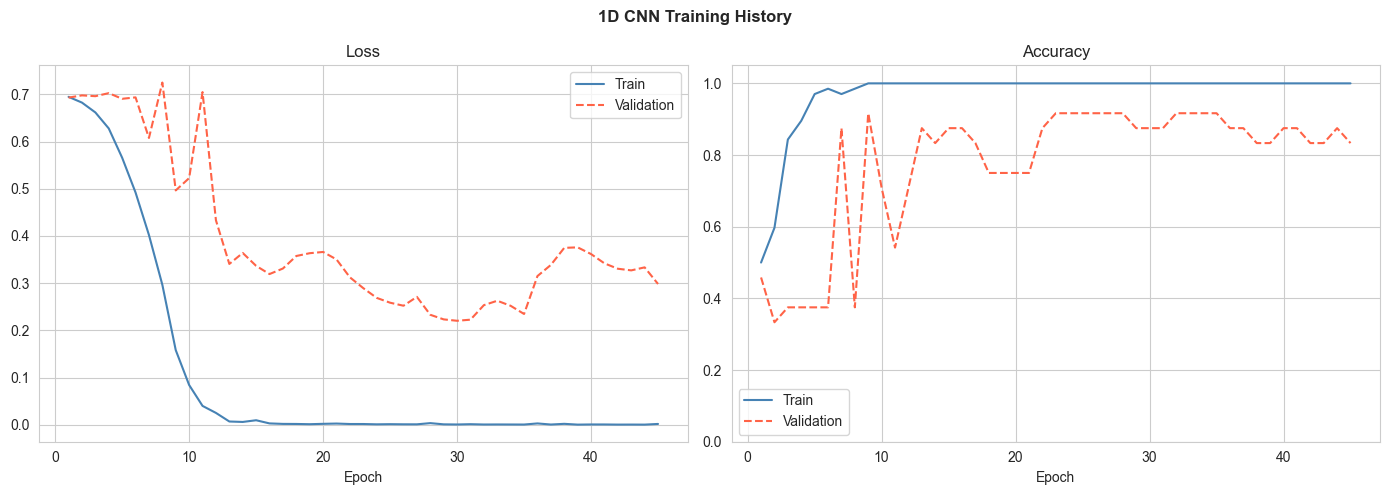

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ep = range(1, len(history.history["loss"]) + 1)

ax1.plot(ep, history.history["loss"],     label="Train",      color="steelblue")
ax1.plot(ep, history.history["val_loss"], label="Validation", color="tomato", linestyle="--")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(ep, history.history["accuracy"],     label="Train",      color="steelblue")
ax2.plot(ep, history.history["val_accuracy"], label="Validation", color="tomato", linestyle="--")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.set_ylim(0, 1.05); ax2.legend()

plt.suptitle("1D CNN Training History", fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Evaluate on Test Set (Lecture 7)

In [7]:
y_prob = cnn_model.predict(X_test_pad, verbose=0).flatten()
y_pred = (y_prob >= 0.5).astype(int)

cnn_acc = accuracy_score(y_test, y_pred)
cnn_f1  = f1_score(y_test, y_pred, average="macro")

print(f"Test Accuracy : {cnn_acc:.2%}")
print(f"Macro F1      : {cnn_f1:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=["Factual", "Fake"]))

Test Accuracy : 95.00%
Macro F1      : 0.9499

              precision    recall  f1-score   support

     Factual       0.91      1.00      0.95        20
        Fake       1.00      0.90      0.95        20

    accuracy                           0.95        40
   macro avg       0.95      0.95      0.95        40
weighted avg       0.95      0.95      0.95        40



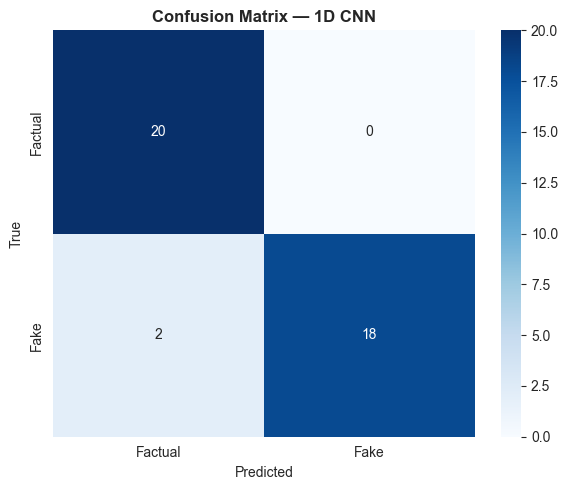

TP (Fake correctly caught)    : 18
TN (Factual correctly passed) : 20
FP (Factual flagged as Fake)  : 0
FN (Fake missed as Factual)   : 2


In [8]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Factual", "Fake"],
            yticklabels=["Factual", "Fake"], ax=ax)
ax.set_title("Confusion Matrix — 1D CNN", fontweight="bold")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TP (Fake correctly caught)    : {tp}")
print(f"TN (Factual correctly passed) : {tn}")
print(f"FP (Factual flagged as Fake)  : {fp}")
print(f"FN (Fake missed as Factual)   : {fn}")

## 8. CNN vs Feedforward NN — Final Comparison

Both models solve the same task but approach text very differently:

| | Feedforward NN (Notebook 02) | 1D CNN (this notebook) |
|---|---|---|
| **Input** | TF-IDF (bag-of-words) | Token sequences (word order preserved) |
| **Feature extraction** | Dense layers (global patterns) | Convolutional filters (local n-gram patterns) |
| **Pooling** | None | MaxPooling1D + GlobalMaxPooling1D |
| **Parameters** | ~912 K | See summary above |

In [9]:
comparison = pd.DataFrame([
    {
        "Model": "Feedforward NN (Notebook 02)",
        "Input": "TF-IDF",
        "Test Accuracy": "97.50%",
        "Architecture": "Dense 256→128→64→1",
    },
    {
        "Model": "1D CNN (this notebook)",
        "Input": "Embedding + sequences",
        "Test Accuracy": f"{cnn_acc:.2%}",
        "Architecture": "Embed→Conv1D→Pool→Conv1D→GlobalPool→Dense→1",
    },
])
print(comparison.to_string(index=False))

                       Model                 Input Test Accuracy                                Architecture
Feedforward NN (Notebook 02)                TF-IDF        97.50%                          Dense 256→128→64→1
      1D CNN (this notebook) Embedding + sequences        95.00% Embed→Conv1D→Pool→Conv1D→GlobalPool→Dense→1
